# Week 5 Notebook
Late-start week: Monday's and Tuesday's games were missed, so the window is Wednesday to Sunday and most teams have only 2 games (range 1 to 3). Same model (v1, frozen through Week 6). Opponents were entered by hand and my lineup is unchanged apart from the opponent changes.

In [1]:
!rm -f data_pull.py data_pull.py.* scoring.py scoring.py.* stats.py stats.py.* matchup.py matchup.py.*
!wget -q -O data_pull.py https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/src/data_pull.py
!wget -q -O scoring.py https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/src/scoring.py
!wget -q -O stats.py https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/src/stats.py
!wget -q -O matchup.py https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/src/matchup.py

!mkdir -p predictions
!wget -q -O predictions/week01.csv https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/predictions/week01.csv
!wget -q -O predictions/week02.csv https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/predictions/week02.csv
!wget -q -O predictions/week02.csv https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/predictions/week03.csv
!wget -q -O predictions/week04.csv https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/predictions/week04.csv

from data_pull import get_player_id, get_game_log, get_games_in_window #type: ignore
from scoring import SKATER_FIELD_MAP, GOALIE_FIELD_MAP #type: ignore
from stats import get_player_estimates, get_prior_season_stats, _scored_game_log #type: ignore
from matchup import compare_players, compare_weekly #type: ignore

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
SEASON = "20262027"
PRIOR_SEASON = "20252026"


# Week 4 (being graded): full Monday to Sunday
WEEK4 = {lg: ("2026-10-19", "2026-10-25") for lg in ("league_1", "league_2", "league_3")}

# Week 5 (being predicted): late start, I apologize. Monday Oct 26 and Tues Oct 28 was missed, so this is Wedensday to Sunday.
WEEK5 = {lg: ("2026-10-28", "2026-11-01") for lg in ("league_1", "league_2", "league_3")}

league_scoring = {
    "league_1": {
        "skater": {"G": 2, "A": 1, "PIM": -0.25, "PPG": 0.5, "SHG": 2, "SHA": 1, "GWG": 1, "SOG": 0.1, "HIT": 0.25, "BLK": 0.25},
        "goalie": {"W": 5, "GA": -1, "SV": 0.1, "SHO": 5},
    },
    "league_2": {
        "skater": {"G": 2.5, "A": 1.5, "PIM": -0.25, "PPG": 0.5, "PPA": 0.25, "SHG": 1, "SHA": 0.5, "GWG": 1, "SOG": 0.1, "HIT": 0.4, "BLK": 0.5},
        "goalie": {"W": 5, "GA": -1, "SV": 0.15, "SHO": 5},
    },
    "league_3": {
        "skater": {"G": 2.55, "A": 2.37, "PPP": 1.77, "SHP": 1.73, "GWG": 3.0, "SOG": 0.1, "HIT": 0.2, "BLK": 0.15},
        "goalie": {"W": 3.85, "GA": -0.05, "SV": 0.03, "SHO": 5.75},
    },
}

SLEEPERS_W4 = ["Adam Edstrom", "Michael Brandsegg-Nygard", "Boone Jenner"]   # graded in the recap
SLEEPER_POSITION = {}   # all skaters

_id_cache = {}
def resolve_id(player):
    if isinstance(player, (int, np.integer)):
        return int(player)
    if player not in _id_cache:
        _id_cache[player] = get_player_id(player)
    return _id_cache[player]

def cfg_and_map(league, position):
    side = "goalie" if position == "G" else "skater"
    return league_scoring[league][side], (GOALIE_FIELD_MAP if position == "G" else SKATER_FIELD_MAP)

In [3]:
BLUE, ORANGE, GRAY, INK, MUTED, LIGHT = "#2a78d6", "#eb6834", "#a8a69f", "#0b0b0b", "#52514e", "#9cc3ee"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10,
})

import time
_refreshed = set()

def window_stats(player, position, league, start, end):
    """Games and total fantasy points for one player in a date window, under one league's scoring."""
    pid = resolve_id(player)
    cfg, fmap = cfg_and_map(league, position)
    log = None
    for attempt in range(6):
        try:
            log = _scored_game_log(pid, SEASON, position, cfg, fmap, force_refresh=(pid not in _refreshed))
            _refreshed.add(pid)
            break
        except Exception as e:
            if "429" in str(e) and attempt < 5:
                time.sleep(10 * (attempt + 1))   # back off 10s, 20s, 30s...
                continue
            raise
    if log is None:
        return {"games": 0, "total": 0.0}
    d = log[(log["gameDate"] >= pd.Timestamp(start)) & (log["gameDate"] <= pd.Timestamp(end))]
    return {"games": len(d), "total": float(d["fantasy_points"].sum())}

def outcome(a, b):
    return 1.0 if a > b else (0.0 if a < b else 0.5)

from stats import build_full_skater_log  #type: ignore

def toi_minutes(value):
    try:
        m, s = str(value).split(":")
        return int(m) + int(s) / 60
    except Exception:
        return np.nan

def process_window(name, season, start=None, end=None):
    log = build_full_skater_log(resolve_id(name), season, include_hits_blocks=False)
    if log.empty:
        return None
    if start is not None:
        d = pd.to_datetime(log["gameDate"])
        log = log[(d >= pd.Timestamp(start)) & (d <= pd.Timestamp(end))]
    if log.empty:
        return None
    shots, goals = log["shots"].sum(), log["goals"].sum()
    return {"games": len(log), "pts_per_game": log["points"].mean(), "shots_per_game": log["shots"].mean(),
            "shooting_pct": goals / shots if shots else np.nan,
            "toi_per_game": log["toi"].map(toi_minutes).mean() if "toi" in log.columns else np.nan}

def goalie_process(name, season, start=None, end=None):
    log = get_game_log(resolve_id(name), season=season)
    if log.empty:
        return None
    if start is not None:
        d = pd.to_datetime(log["gameDate"])
        log = log[(d >= pd.Timestamp(start)) & (d <= pd.Timestamp(end))]
        if log.empty:
            return None
    def num(col):
        return pd.to_numeric(log[col], errors="coerce") if col in log.columns else pd.Series(np.nan, index=log.index)
    team = log["teamAbbrev"].iloc[-1] if "teamAbbrev" in log.columns else None
    team_games = len(get_games_in_window(team, start, end)) if (start is not None and team) else 82
    ga, sa, starts = num("goalsAgainst").sum(), num("shotsAgainst").sum(), num("gamesStarted").sum()
    return {"games": len(log), "starts": starts, "team_games": team_games,
            "start_share": starts / team_games if team_games else np.nan,
            "wins": int((log["decision"] == "W").sum()) if "decision" in log.columns else np.nan,
            "sv_pct": 1 - ga / sa if sa else np.nan, "ga_per_game": ga / len(log)}

# Week 5 Predictions (Wed Oct 28 to Sun Nov 1)



In [4]:

matchups_w5 = {
        "league_1": [
        {"position": "C", "me": "Connor McDavid", "opponent": "Morgan Geekie"},
        {"position": "C", "me": "Tim Stutzle", "opponent": "Pavel Zacha"},
        {"position": "LW", "me": "Filip Forsberg", "opponent": "Jason Robertson"},
        {"position": "LW", "me": "Kyle Connor", "opponent": "Andrei Svechnikov"},
        {"position": "RW", "me": "Wyatt Johnston", "opponent": "Jack Quinn"},
        {"position": "RW", "me": "Alex Tuch", "opponent": "Vasily Podkolzin"},
        {"position": "D", "me": "Jakob Chychrun", "opponent": "Shayne Gostisbehere"},
        {"position": "D", "me": "Mackenzie Weegar", "opponent": "Zach Werenski"},
        {"position": "D", "me": "Noah Dobson", "opponent": "Vince Dunn"},
        {"position": "D", "me": "Mattias Samuelsson", "opponent": "Morgan Rielly"},
        {"position": "UTIL", "me": "Seth Jarvis", "opponent": "Matthew Tkachuk"},
        {"position": "G", "me": "Jeremy Swayman", "opponent": "Connor Hellebuyck"},
        {"position": "G", "me": "Jake Oettinger", "opponent": "Pyotr Kochetkov"},
    ],
    "league_2": [
        {"position": "C", "me": "Nathan MacKinnon", "opponent": "Mason McTavish"},
        {"position": "C", "me": "Sebastian Aho", "opponent": "Jack Eichel"},
        {"position": "LW", "me": "Filip Forsberg", "opponent": "Nazem Kadri"},
        {"position": "LW", "me": "Tim Stutzle", "opponent": "Bobby McMann"},
        {"position": "RW", "me": "Matt Boldy", "opponent": "Jesper Bratt"},
        {"position": "RW", "me": "Drake Batherson", "opponent": "Clayton Keller"},
        {"position": "D", "me": "Jakob Chychrun", "opponent": "Miro Heiskanen"},
        {"position": "D", "me": "Jackson LaCombe", "opponent": "Noah Dobson"},
        {"position": "D", "me": "Mattias Samuelsson", "opponent": "Zach Werenski"},
        {"position": "D", "me": "Charlie McAvoy", "opponent": "Devon Toews"},
        {"position": "UTIL", "me": "Sam Reinhart", "opponent": "Kirill Kaprizov"},
        {"position": "UTIL", "me": "Elias Pettersson", "opponent": "Jake Guentzel"},
        {"position": "G", "me": "Jake Oettinger", "opponent": "Brandon Bussi"},
        {"position": "G", "me": "Mackenzie Blackwood", "opponent": "Scott Wedgewood"},
    ],

    "league_3": [
        {"position": "C", "me": "Connor McDavid", "opponent": "Jack Eichel"},
        {"position": "C", "me": "Auston Matthews", "opponent": "Pavel Zacha"},
        {"position": "C", "me": "Tim Stutzle", "opponent": "Elias Pettersson"},
        {"position": "LW", "me": "Kyle Connor", "opponent": "Zach Benson"},
        {"position": "LW", "me": "Clayton Keller", "opponent": "Cole Caufield"},
        {"position": "LW", "me": "J.T. Miller", "opponent": "Drake Batherson"},
        {"position": "RW", "me": "Martin Necas", "opponent": "Jack Quinn"},
        {"position": "RW", "me": "Sam Reinhart", "opponent": "Lucas Raymond"},
        {"position": "RW", "me": "Will Cuylle", "opponent": "Nick Schmaltz"},
        {"position": "F", "me": "Alex Ovechkin", "opponent": "Dylan Cozens"},
        {"position": "F", "me": "Tom Wilson", "opponent": "Tage Thompson"},
        {"position": "D", "me": "Jakob Chychrun", "opponent": "Vince Dunn"},
        {"position": "D", "me": "Mikhail Sergachev", "opponent": "Morgan Rielly"},
        {"position": "D", "me": "Thomas Harley", "opponent": "Roman Josi"},
        {"position": "D", "me": "Rasmus Andersson", "opponent": "Jacob Trouba"},
        {"position": "UTIL", "me": "Brock Nelson", "opponent": "Jake Guentzel"},
        {"position": "G", "me": "Karel Vejmelka", "opponent": "Mackenzie Blackwood"},
        {"position": "G", "me": "Jakub Dobes", "opponent": "Illya Sorokin"},
    ],
}

In [5]:
# Only needed when the automatic team lookup gets someone wrong, name -> NHL team abbreviation
TEAM_OVERRIDES = {
    # "Some Player": "TOR",
}

# Only needed to override the automatic goalie start-share, name -> share of team games he starts (0 to 1)
GOALIE_START_SHARE = {
    # "Devon Levi": 0.6,
}

def current_team(player):
    """Most recent team from the game log, this season first, then last season. Returns (team, source)."""
    if player in TEAM_OVERRIDES:
        return TEAM_OVERRIDES[player], "override"
    pid = resolve_id(player)
    for season, source in ((SEASON, "this season"), (PRIOR_SEASON, "last season, VERIFY")):
        log = get_game_log(pid, season=season)
        if not log.empty and "teamAbbrev" in log.columns:
            return log.sort_values("gameDate").iloc[-1]["teamAbbrev"], source
    return None, "not found"

def goalie_start_share(player):
    """Share of his team's games a goalie starts, from last season's starts out of 82, unless overridden."""
    if player in GOALIE_START_SHARE:
        return GOALIE_START_SHARE[player]
    log = get_game_log(resolve_id(player), season=PRIOR_SEASON)
    if log.empty or len(log) < 20 or "gamesStarted" not in log.columns:
        return 0.5
    starts = pd.to_numeric(log["gamesStarted"], errors="coerce").fillna(0).sum()
    return float(min(max(starts / 82, 0.15), 0.95))

def is_placeholder(value):
    return isinstance(value, str) and (value.startswith("None") or "suspended" in value.lower())

def run_weekly_comparisons(league):
    start, end = WEEK5[league]
    results = []
    for m in matchups_w5[league]:
        pos = m["position"]
        base = {"week": 5, "league": league, "position": pos, "me": m["me"], "opponent": m["opponent"]}

        if is_placeholder(m["me"]) or is_placeholder(m["opponent"]):
            results.append({**base, "note": "no real comparison in this slot"})
            continue

        cfg, fmap = cfg_and_map(league, pos)
        me_id, opp_id = resolve_id(m["me"]), resolve_id(m["opponent"])
        me_est = get_player_estimates(me_id, pos, cfg, fmap, season=SEASON, prior_season=PRIOR_SEASON)
        opp_est = get_player_estimates(opp_id, pos, cfg, fmap, season=SEASON, prior_season=PRIOR_SEASON)
        if me_est is None or opp_est is None:
            results.append({**base, "note": f"skipped (no data: me={me_est is not None}, opp={opp_est is not None})"})
            continue

        me_team, me_src = current_team(m["me"])
        opp_team, opp_src = current_team(m["opponent"])
        if me_team is None or opp_team is None:
            results.append({**base, "note": "skipped (could not find a team, add a TEAM_OVERRIDES entry)"})
            continue

        me_games = len(get_games_in_window(me_team, start, end))
        opp_games = len(get_games_in_window(opp_team, start, end))
        me_share = goalie_start_share(m["me"]) if pos == "G" else 1.0
        opp_share = goalie_start_share(m["opponent"]) if pos == "G" else 1.0

        kwargs = dict(label_a=str(m["me"]), label_b=str(m["opponent"]), start_share_a=me_share, start_share_b=opp_share)
        weekly = compare_weekly(me_est, me_games, opp_est, opp_games, use="season", **kwargs)
        weekly_recent = compare_weekly(me_est, me_games, opp_est, opp_games, use="recent", **kwargs)
        per_game = compare_players(me_est, opp_est, str(m["me"]), str(m["opponent"]))

        p = weekly["probability_a_outperforms_b"]
        notes = []
        if "VERIFY" in me_src or "VERIFY" in opp_src:
            notes.append("team taken from last season, verify")
        if me_games == 0 or opp_games == 0:
            notes.append("a player has no games this week")
        results.append({
            **base,
            "me_team": me_team, "opp_team": opp_team,
            "me_games": me_games, "opp_games": opp_games,
            "me_start_share": me_share if pos == "G" else np.nan,
            "opp_start_share": opp_share if pos == "G" else np.nan,
            "me_week_mu": weekly["mu_a"], "opp_week_mu": weekly["mu_b"],
            "me_week_sigma": weekly["sigma_a"], "opp_week_sigma": weekly["sigma_b"],
            "p_me_outperforms": p,
            "confidence": max(p, 1 - p),
            "favored": "me" if p > 0.5 else ("opponent" if p < 0.5 else "even"),
            "p_per_game": per_game["probability_a_outperforms_b"],
            "p_recent_form": weekly_recent["probability_a_outperforms_b"],
            "me_games_so_far": me_est["games_played"], "opp_games_so_far": opp_est["games_played"],
            "low_confidence": bool(me_est["low_confidence"] or opp_est["low_confidence"]),
            "prediction_unit": "weekly_total",
            "model_version": "v1",
            "headline_pick": np.nan,
            "note": "; ".join(notes),
        })
    return pd.DataFrame(results)

active = [lg for lg, ms in matchups_w5.items() if ms]
print("Leagues with matchups:", active or "none yet, paste matchups above and re-run")
week5_results = {lg: run_weekly_comparisons(lg) for lg in active}

Leagues with matchups: ['league_1', 'league_2', 'league_3']
Matched 'Connor McDavid' to 'Connor McDavid'
Matched 'Morgan Geekie' to 'Morgan Geekie'
Loading game log for 8478402, 20262027 from cache, 0.0 hours old
Loading game log for 8478402, 20252026 from cache, 0.5 hours old
Loading game log for 8479987, 20262027 from cache, 0.0 hours old
Loading game log for 8479987, 20252026 from cache, 0.5 hours old
Loading game log for 8478402, 20262027 from cache, 0.0 hours old
Loading game log for 8479987, 20262027 from cache, 0.0 hours old
Matched 'Tim Stutzle' to 'Tim Stützle'
Matched 'Pavel Zacha' to 'Pavel Zacha'
Loading game log for 8482116, 20262027 from cache, 0.0 hours old
Loading game log for 8482116, 20252026 from cache, 0.5 hours old
Loading game log for 8478401, 20262027 from cache, 0.5 hours old
Loading game log for 8478401, 20252026 from cache, 0.5 hours old
Loading game log for 8482116, 20262027 from cache, 0.0 hours old
Loading game log for 8478401, 20262027 from cache, 0.5 hour

In [6]:
all_w5 = pd.concat(week5_results.values(), ignore_index=True)
show = ["position", "me", "opponent", "me_games", "opp_games", "me_week_mu", "opp_week_mu",
        "p_me_outperforms", "p_per_game", "p_recent_form", "low_confidence", "note"]
for league, df in week5_results.items():
    print(f"\n=== {league.upper()} ===")
    d = df.copy()
    for c in ("p_me_outperforms", "p_per_game", "p_recent_form"):
        if c in d:
            d[c] = d[c].map(lambda p: f"{p:.1%}" if pd.notna(p) else "n/a")
    print(d[[c for c in show if c in d.columns]].to_string(index=False, float_format=lambda v: f"{v:.1f}"))

print()
for league, df in week5_results.items():
    d = df[df["p_me_outperforms"].notna()]
    if d.empty:
        continue
    print(f"{league}: favored in {int((d['favored'] == 'me').sum())} of {len(d)} comparable slots, "
          f"{d['p_me_outperforms'].mean():.1%} average win probability across slots")
    for r in d[(d["p_me_outperforms"] - 0.5).abs() < 0.02].itertuples():
        print(f"   coin flip: {r.me} vs {r.opponent} ({r.p_me_outperforms:.1%})")
    for r in d[d["me_games"] != d["opp_games"]].itertuples():
        print(f"   unequal games: {r.me} {r.me_games:.0f} vs {r.opponent} {r.opp_games:.0f}")
    for r in df[df["p_me_outperforms"].isna()].itertuples():
        print(f"   {r.me} vs {r.opponent}: {r.note}")


=== LEAGUE_1 ===
position                 me            opponent  me_games  opp_games  me_week_mu  opp_week_mu p_me_outperforms p_per_game p_recent_form  low_confidence note
       C     Connor McDavid       Morgan Geekie         3          2        11.0          3.2            95.2%      76.5%         97.3%           False     
       C        Tim Stutzle         Pavel Zacha         3          2         8.2          3.0            89.8%      69.0%         88.7%           False     
      LW     Filip Forsberg     Jason Robertson         2          2         4.2          4.7            43.9%      45.7%         48.4%           False     
      LW        Kyle Connor   Andrei Svechnikov         3          2         7.4          4.3            74.7%      54.0%         68.7%           False     
      RW     Wyatt Johnston          Jack Quinn         2          2         4.1          3.3            59.8%      57.0%         56.0%           False     
      RW          Alex Tuch    Vasily Po

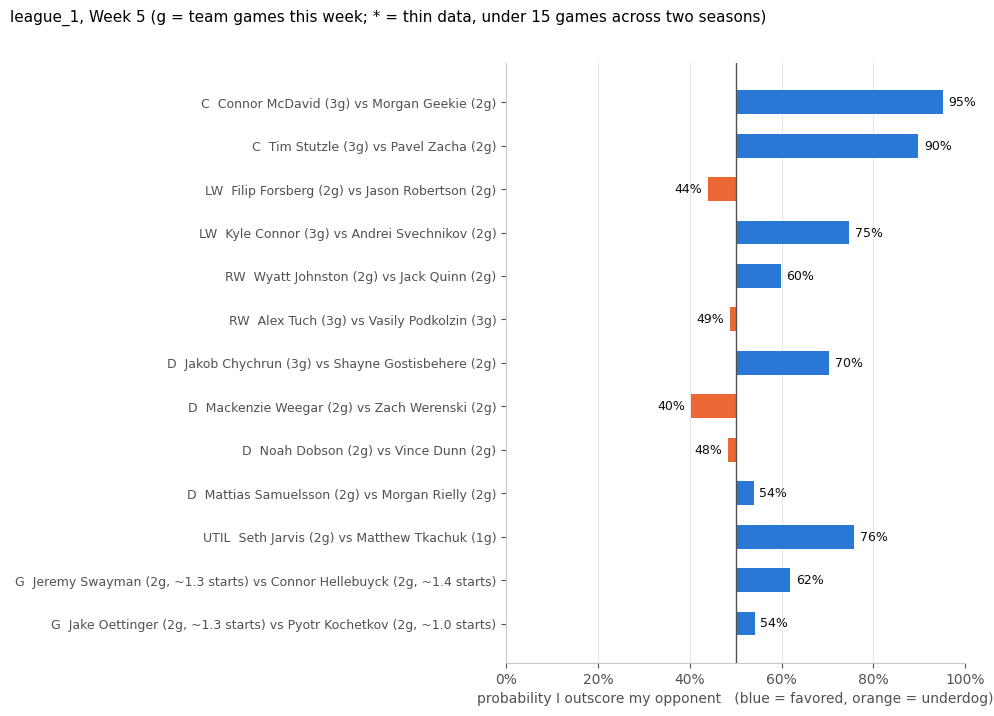

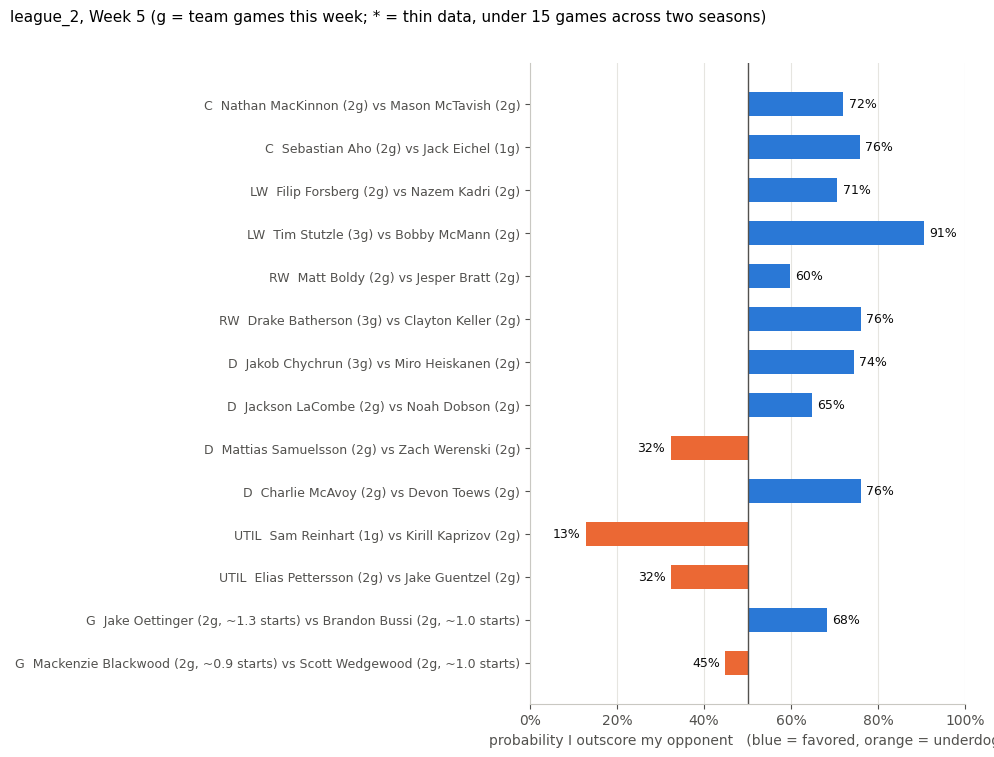

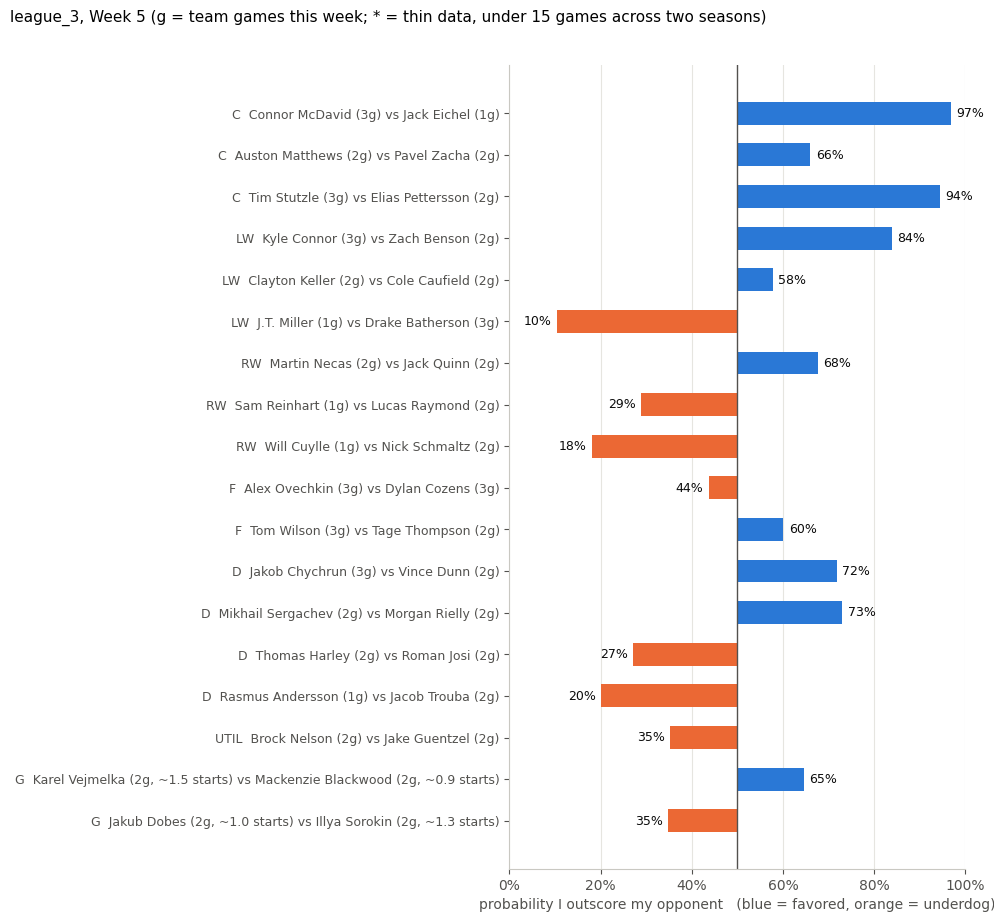

In [7]:
def plot_week5_bars(league, df):
    d = df[df["p_me_outperforms"].notna()].reset_index(drop=True)
    if d.empty:
        return
    y = np.arange(len(d))[::-1]
    colors = np.where(d["p_me_outperforms"] >= 0.5, BLUE, ORANGE)
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(d) + 1.8))
    ax.barh(y, d["p_me_outperforms"] - 0.5, left=0.5, color=colors, height=0.55)
    ax.axvline(0.5, color=MUTED, linewidth=1)
    star = np.where(d["low_confidence"].astype(bool), " *", "")
    def side(name, games, share):
        # a goalie only starts some of his team's games, so show the expected starts too
        return f"{name} ({games:.0f}g)" if pd.isna(share) else f"{name} ({games:.0f}g, ~{games * share:.1f} starts)"
    labels = [f"{r.position}  {side(r.me, r.me_games, r.me_start_share)} vs {side(r.opponent, r.opp_games, r.opp_start_share)}{s}"
              for r, s in zip(d.itertuples(), star)]
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=9)
    for yi, p in zip(y, d["p_me_outperforms"]):
        ax.text(p + (0.012 if p >= 0.5 else -0.012), yi, f"{p:.0%}", va="center",
                ha="left" if p >= 0.5 else "right", fontsize=9, color=INK)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_xlabel("probability I outscore my opponent   (blue = favored, orange = underdog)")
    fig.suptitle(f"{league}, Week 5 (g = team games this week; * = thin data, under 15 games across two seasons)",
                 x=0.01, ha="left", fontsize=11)
    ax.grid(axis="y", visible=False)
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()

for league, df in week5_results.items():
    plot_week5_bars(league, df)

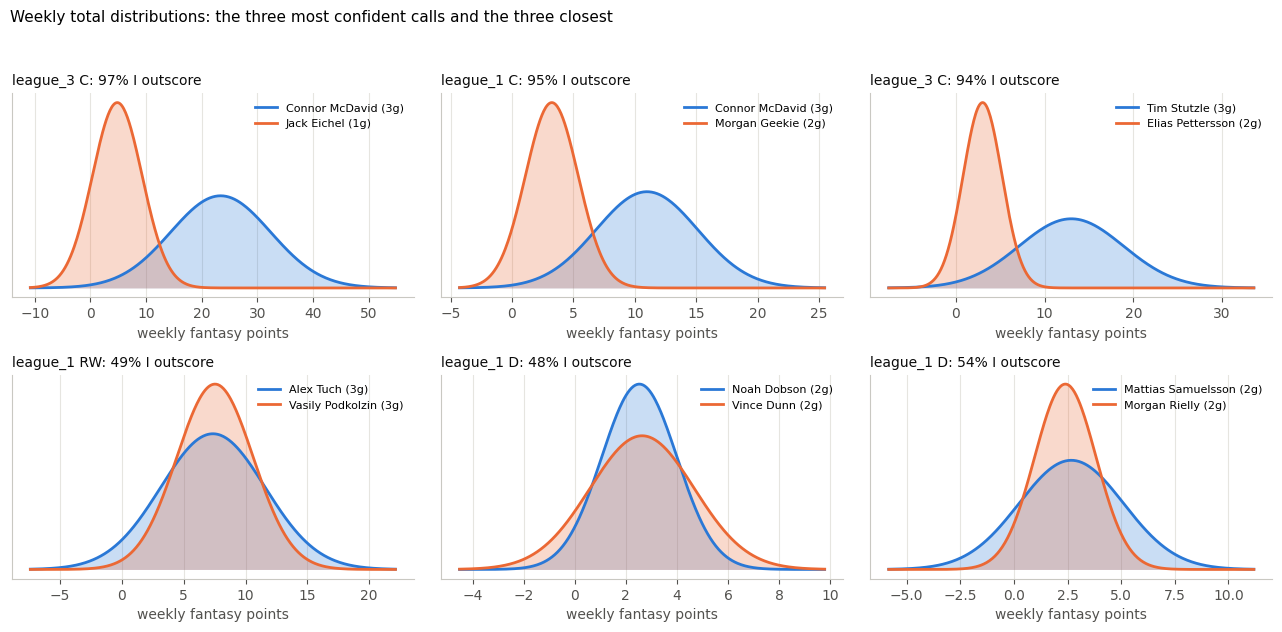

In [8]:
def plot_week5_distributions(all_df, n_each=3):
    ok = all_df[all_df["p_me_outperforms"].notna()]
    firm = ok.sort_values("confidence", ascending=False).head(n_each)
    close = ok.assign(gap=(ok["p_me_outperforms"] - 0.5).abs()).sort_values("gap").head(n_each)
    chosen = pd.concat([firm, close]).drop_duplicates(subset=["league", "me", "opponent"])
    n = len(chosen)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.3 * cols, 3.2 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, r) in zip(axes, chosen.iterrows()):
        lo = min(r["me_week_mu"] - 3.5 * r["me_week_sigma"], r["opp_week_mu"] - 3.5 * r["opp_week_sigma"])
        hi = max(r["me_week_mu"] + 3.5 * r["me_week_sigma"], r["opp_week_mu"] + 3.5 * r["opp_week_sigma"])
        x = np.linspace(max(lo, 0) if lo > -1 else lo, hi, 400)
        ax.fill_between(x, norm.pdf(x, r["me_week_mu"], r["me_week_sigma"]), color=BLUE, alpha=0.25, linewidth=0)
        ax.plot(x, norm.pdf(x, r["me_week_mu"], r["me_week_sigma"]), color=BLUE, linewidth=2, label=f"{r['me']} ({r['me_games']:.0f}g)")
        ax.fill_between(x, norm.pdf(x, r["opp_week_mu"], r["opp_week_sigma"]), color=ORANGE, alpha=0.25, linewidth=0)
        ax.plot(x, norm.pdf(x, r["opp_week_mu"], r["opp_week_sigma"]), color=ORANGE, linewidth=2, label=f"{r['opponent']} ({r['opp_games']:.0f}g)")
        ax.set_title(f"{r['league']} {r['position']}: {r['p_me_outperforms']:.0%} I outscore", loc="left", fontsize=10)
        ax.set_yticks([])
        ax.set_xlabel("weekly fantasy points")
        ax.legend(frameon=False, fontsize=8, loc="upper right")
        ax.grid(axis="y", visible=False)
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle("Weekly total distributions: the three most confident calls and the three closest", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

plot_week5_distributions(all_w5)

In [9]:
g = all_w5[(all_w5["position"] == "G") & all_w5["p_me_outperforms"].notna()].copy()
g["me_exp_starts"] = g["me_games"] * g["me_start_share"]
g["opp_exp_starts"] = g["opp_games"] * g["opp_start_share"]
cols = ["league", "me", "opponent", "me_games", "me_start_share", "me_exp_starts",
        "opp_games", "opp_start_share", "opp_exp_starts",
        "me_week_mu", "opp_week_mu", "p_me_outperforms", "p_per_game"]
print(g[cols].to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nstart_share = share of his team's games he's expected to start (last season's starts / 82 unless overridden)")
print("exp_starts = team games this week x start_share")

  league                  me            opponent  me_games  me_start_share  me_exp_starts  opp_games  opp_start_share  opp_exp_starts  me_week_mu  opp_week_mu  p_me_outperforms  p_per_game
league_1      Jeremy Swayman   Connor Hellebuyck         2            0.66           1.32          2             0.70            1.39        4.81         2.75              0.62        0.62
league_1      Jake Oettinger     Pyotr Kochetkov         2            0.66           1.32          2             0.50            1.00        5.72         4.88              0.54        0.47
league_2      Jake Oettinger       Brandon Bussi         2            0.66           1.32          2             0.48            0.95        7.10         3.45              0.68        0.62
league_2 Mackenzie Blackwood     Scott Wedgewood         2            0.44           0.88          2             0.52            1.05        3.63         4.58              0.45        0.48
league_3      Karel Vejmelka Mackenzie Blackwood       

**What stands out in Week 5:**
- I'm favored in 29 of 45 slots: league 1 in 9 of 13 (62.8% average), league 2 in 10 of 14 (60.8%), league 3 in 10 of 18 (53.0%). 19 of the 45 have unequal game counts.
- With only 2 games for most players, one bad night moves a whole matchup, so results will be noisier than a full week.
- Biggest calls: McDavid 95% (L1) and 97% (L3), Stutzle 90% to 94% in all three leagues, Kyle Connor 75% to 84%. Most of these come with an extra game over the opponent.
- Several slots are underdogs only because of games: J.T. Miller (1 game vs 3, 10%), Sam Reinhart (1 game, 13% in L2 and 29% in L3), Will Cuylle (1 game, 18%) and Rasmus Andersson (1 game, 20%). Those are worth checking against the lineup.
- Closest calls: Tuch vs Podkolzin (48.7%), Dobson vs Dunn (48.3%) and, in the goalie slots, Blackwood vs Wedgewood (45%) and Oettinger vs Kochetkov (54%). Expected goalie starts run from about 0.9 to 1.5.
- Week 4's 70%+ calls went only 4 of 14, so treat this week's high-confidence calls as less certain than the numbers say.

**Headline picks:**
- McDavid over Geekie (league 1, 95%): 3 games vs 2, per-game 76%, recent form 97%.
- McAvoy over Toews (league 2, 76%): equal games, per-game 69%, recent form 66%.
- Stutzle over Pettersson (league 3, 94%): 3 games vs 2, per-game 78%, recent form 92%.

In [10]:
HEADLINE_PICKS = [
    ("league_1", "Connor McDavid", "Morgan Geekie"),     # 95%, 3g vs 2g, per-game 76%, recent 97%
    ("league_2", "Charlie McAvoy", "Devon Toews"),       # 76%, equal games (2g each), per-game 69%, recent 66%
    ("league_3", "Tim Stutzle", "Elias Pettersson"),     # 94%, 3g vs 2g, per-game 78%, recent 92%
]
assert len(HEADLINE_PICKS) == 3, "pick exactly three headline calls"

import os
out = pd.concat(week5_results.values(), ignore_index=True)
out["headline_pick"] = False
for lg, me, opp in HEADLINE_PICKS:
    mask = (out["league"] == lg) & (out["me"] == me) & (out["opponent"] == opp)
    assert mask.sum() == 1, f"headline pick not found: {lg} {me} vs {opp}"
    out.loc[mask, "headline_pick"] = True
out["window_start"], out["window_end"] = WEEK5["league_1"]
out["late_start"] = WEEK5["league_1"][0] != "2026-10-26"   # True unless the window starts on the Monday
out["source"] = "model_v1"
os.makedirs("predictions", exist_ok=True)
out.to_csv("predictions/week05.csv", index=False)
print(out.shape, out["headline_pick"].sum(), "headline picks")
try:
    from google.colab import files  # type: ignore
    files.download("predictions/week05.csv")
except ImportError:
    pass

(45, 31) 3 headline picks


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Week 5 sleepers

Three low-rostered skaters, chosen before the games.

| Player | Team | Rostered | Team games | Thesis |
|---|---|---|---|---|
| Tye Kartye | NYR | 4% | 1 | Second-line minutes (about 15) and 2.4 hits per game give a floor, but 6 points on 9 shots is thin volume, so the bet is hits plus a few points, not a scoring surge. |
| Tim Washe | ANA | 5% | 2 | Fourth-line centre who racks up hits (about 3.6 per game) and blocks (about 1.7), worth the most in League 2, so the floor comes from that and not from points. |
| Maxim Shabanov | MIN | 5% | 2 | Promoted to the top power play, so the bet is that the added power-play time keeps him producing on 2 games this week. |

Process check from the table: all three have more ice time than last season (Kartye 15.5 vs 12.0 minutes, Washe 15.6 vs 12.1, Shabanov 14.7 vs 13.7). Shabanov's 24% shooting is well above his 9% last season, so some of his start is shooting luck, and Kartye has only one team game this week. Hits and blocks aren't in this table, so the hits-and-blocks part of the Kartye and Washe theses can't be checked from it.

In [11]:
SLEEPERS_W5 = ["Tye Kartye", "Tim Washe", "Maxim Shabanov"]   # chosen before the games
SLEEPER_POSITION_W5 = {}   # all skaters
ROSTERED_W5 = {"Tye Kartye": 0.04, "Tim Washe": 0.05, "Maxim Shabanov": 0.05}   # rostered % as a fraction, e.g. 0.22
SEASON_START = "2026-09-01"
TODAY = (pd.Timestamp(WEEK5["league_1"][0]) - pd.Timedelta(days=1)).strftime("%Y-%m-%d")   # "this season so far", through the day before the window

In [12]:
SLEEPER_THESIS_W5 = {
    "Tye Kartye": "Second-line minutes (about 15) and 2.4 hits per game give a floor, but 6 points on 9 shots is thin volume, so the bet is hits plus a few points, not a scoring surge.",
    "Tim Washe": "Fourth-line centre who racks up hits (about 3.6 per game) and blocks (about 1.7), which are worth the most in League 2, so the floor comes from that and not from points.",
    "Maxim Shabanov": "Promoted to the top power play, so the bet is that the added power-play time keeps him producing on 2 to 3 games this week.",
}

In [13]:
rows = []
for name in SLEEPERS_W5:
    pos = SLEEPER_POSITION_W5.get(name, "F")
    pid = resolve_id(name)
    team, src = current_team(name)
    team_games = len(get_games_in_window(team, *WEEK5["league_1"])) if team else np.nan
    share = goalie_start_share(name) if pos == "G" else np.nan
    for league in ("league_1", "league_2", "league_3"):
        cfg, fmap = cfg_and_map(league, pos)
        now = window_stats(name, pos, league, SEASON_START, TODAY)
        avg = now["total"] / now["games"] if now["games"] else np.nan
        prior_mu, _ = get_prior_season_stats(pid, PRIOR_SEASON, pos, cfg, fmap)
        est = get_player_estimates(pid, pos, cfg, fmap, season=SEASON, prior_season=PRIOR_SEASON)
        rows.append({
            "player": name, "pos": pos, "team": team, "league": league, "rostered": ROSTERED_W5.get(name),
            "games": now["games"], "this_season_avg": avg, "last_season_avg": prior_mu,
            "vs_last_season": (avg / prior_mu - 1) if prior_mu and not pd.isna(avg) else np.nan,
            "season_mu": est["season_mu"] if est else np.nan,
            "recent_mu": est["recent_mu"] if est else np.nan,
            "week5_team_games": team_games, "start_share": share,
            "exp_games_week5": team_games * share if pos == "G" else team_games,
            "low_confidence": est["low_confidence"] if est else np.nan,
        })
sleepers_w5 = pd.DataFrame(rows)
print(sleepers_w5.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nseason_mu = this season's games blended toward last season (what the predictions use)")
print("recent_mu = recent form across last season into this one;  exp_games_week5 for a goalie = team games x start share")

Matched 'Tye Kartye' to 'Tye Kartye'
Loading game log for 8481789, 20262027 from cache, 0.0 hours old
Pulling fresh game log for 8481789, 20262027
Loading game log for 8481789, 20252026 from cache, 0.3 hours old
Loading game log for 8481789, 20262027 from cache, 0.0 hours old
Loading game log for 8481789, 20252026 from cache, 0.3 hours old
Loading game log for 8481789, 20262027 from cache, 0.0 hours old
Loading game log for 8481789, 20252026 from cache, 0.3 hours old
Loading game log for 8481789, 20262027 from cache, 0.0 hours old
Loading game log for 8481789, 20252026 from cache, 0.3 hours old
Loading game log for 8481789, 20262027 from cache, 0.0 hours old
Loading game log for 8481789, 20252026 from cache, 0.3 hours old
Loading game log for 8481789, 20262027 from cache, 0.0 hours old
Loading game log for 8481789, 20252026 from cache, 0.3 hours old
Matched 'Tim Washe' to 'Tim Washe'
Loading game log for 8485512, 20262027 from cache, 0.0 hours old
Pulling fresh game log for 8485512, 20

In [14]:
skater_rows, goalie_rows = [], []
for name in SLEEPERS_W5:
    for label, season, s, e in (("This season", SEASON, SEASON_START, TODAY), ("Last season", PRIOR_SEASON, None, None)):
        if SLEEPER_POSITION_W5.get(name, "F") == "G":
            r = goalie_process(name, season, s, e)
            if r: goalie_rows.append({"player": name, "period": label, **r})
        else:
            r = process_window(name, season, s, e)
            if r: skater_rows.append({"player": name, "period": label, **r})

sleepers_process_w5 = pd.DataFrame(skater_rows)
sleepers_goalie_w5 = pd.DataFrame(goalie_rows)
print("Skaters:")
print(sleepers_process_w5.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nGoalies (start_share = starts / his team's games):")
print(sleepers_goalie_w5.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nA hot start built on shots and ice time tends to last. One built on a high shooting % usually doesn't.")

Loading game log for 8481789, 20262027 from cache, 0.0 hours old
Loading game log for 8481789, 20252026 from cache, 0.3 hours old
Loading game log for 8485512, 20262027 from cache, 0.0 hours old
Loading game log for 8485512, 20252026 from cache, 0.3 hours old
Loading game log for 8485702, 20262027 from cache, 0.0 hours old
Loading game log for 8485702, 20252026 from cache, 0.3 hours old
Skaters:
        player      period  games  pts_per_game  shots_per_game  shooting_pct  toi_per_game
    Tye Kartye This season     14          0.71            1.50          0.19         15.48
    Tye Kartye Last season     64          0.34            0.88          0.14         11.96
     Tim Washe This season     12          0.50            1.17          0.21         15.59
     Tim Washe Last season     39          0.13            0.85          0.06         12.05
Maxim Shabanov This season     13          0.69            1.31          0.24         14.72
Maxim Shabanov Last season     44          0.41  

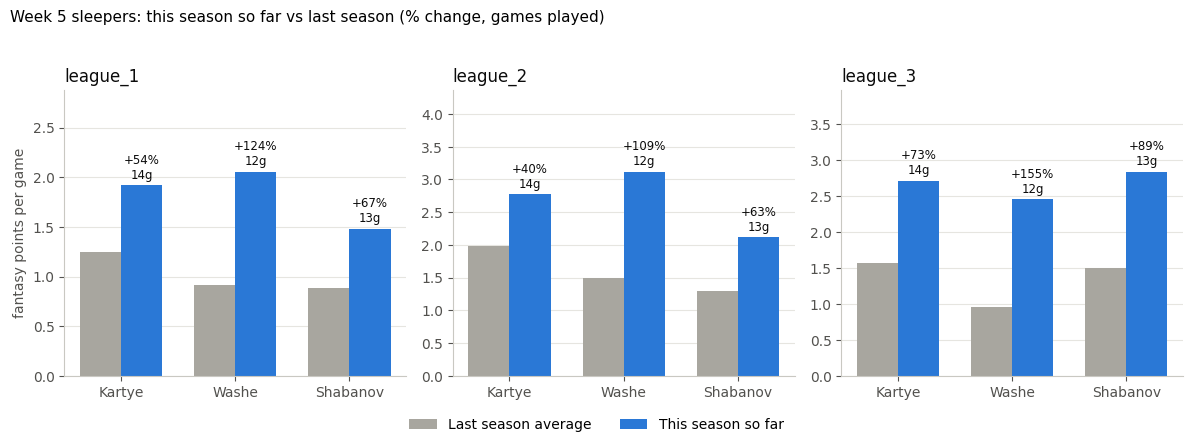

Loading game log for 8481789, 20262027 from cache, 0.0 hours old
Loading game log for 8481789, 20252026 from cache, 0.3 hours old
Loading game log for 8485512, 20262027 from cache, 0.0 hours old
Loading game log for 8485512, 20252026 from cache, 0.3 hours old
Loading game log for 8485702, 20262027 from cache, 0.0 hours old
Loading game log for 8485702, 20252026 from cache, 0.3 hours old


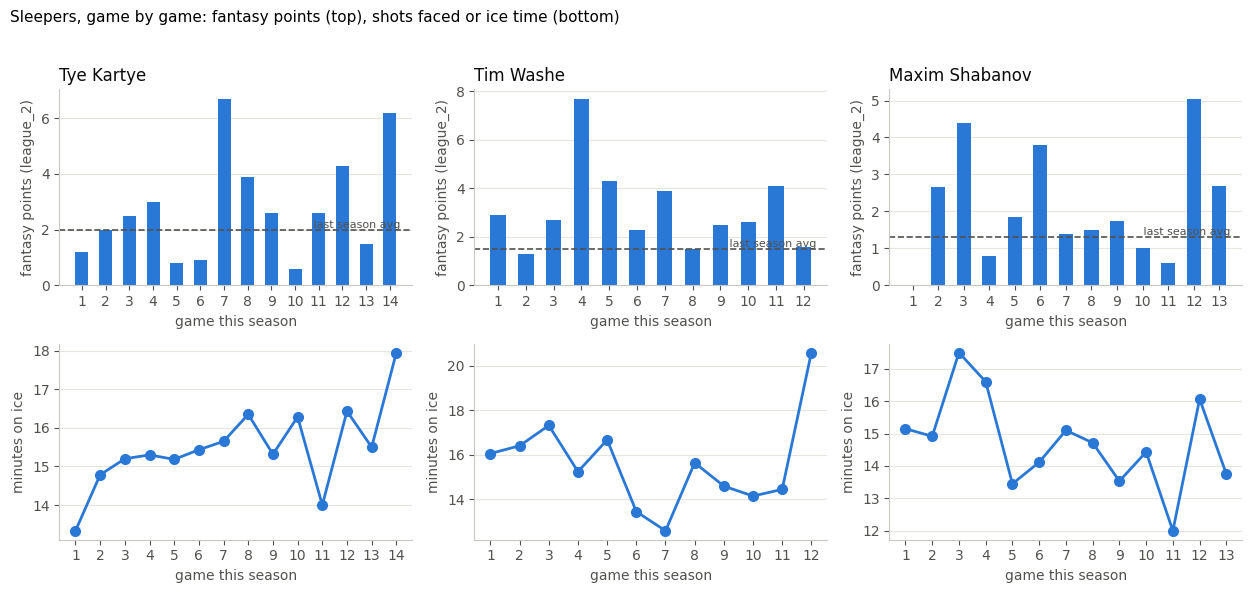

In [15]:
def plot_sleepers_w5(df):
    leagues = sorted(df["league"].unique())
    players = list(dict.fromkeys(df["player"]))
    fig, axes = plt.subplots(1, len(leagues), figsize=(4.0 * len(leagues), 4.4))
    axes = np.atleast_1d(axes)
    x = np.arange(len(players)); w = 0.36
    for ax, league in zip(axes, leagues):
        d = df[df["league"] == league].set_index("player").loc[players]
        ax.bar(x - w/2, d["last_season_avg"], w, color=GRAY, label="Last season average")
        ax.bar(x + w/2, d["this_season_avg"], w, color=BLUE, label="This season so far")
        top = np.nanmax([d["last_season_avg"].max(), d["this_season_avg"].max()])
        for xi, (_, r) in zip(x, d.iterrows()):
            if pd.isna(r["this_season_avg"]):
                continue
            lab = (f"{r['vs_last_season']:+.0%}\n{int(r['games'])}g" if pd.notna(r["vs_last_season"])
                   else f"{int(r['games'])}g\nno prior\nNHL games")
            ax.text(xi + w/2, r["this_season_avg"] + top * 0.02, lab, ha="center", va="bottom", fontsize=8.5, color=INK)
        ax.set_ylim(0, top * 1.4)
        ax.set_xticks(x); ax.set_xticklabels([p.split()[-1] for p in players])
        ax.set_title(league, loc="left"); ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("fantasy points per game")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=2, frameon=False)
    fig.suptitle("Week 5 sleepers: this season so far vs last season (% change, games played)", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0.06, 1, 0.95)); plt.show()

plot_sleepers_w5(sleepers_w5)

def plot_sleeper_games_w5(league="league_2"):
    n = len(SLEEPERS_W5)
    fig, axes = plt.subplots(2, n, figsize=(4.2 * n, 6), squeeze=False)
    for j, name in enumerate(SLEEPERS_W5):
        pos = SLEEPER_POSITION_W5.get(name, "F")
        cfg, fmap = cfg_and_map(league, pos)
        pid = resolve_id(name)
        cur = _scored_game_log(pid, SEASON, pos, cfg, fmap, force_refresh=False)
        last_avg = get_prior_season_stats(pid, PRIOR_SEASON, pos, cfg, fmap)[0]
        ax, ax2 = axes[0, j], axes[1, j]
        if cur is None or cur.empty:
            ax.set_title(f"{name}: no games yet", loc="left"); continue
        cur = cur.reset_index(drop=True)
        g = np.arange(1, len(cur) + 1)
        ax.bar(g, cur["fantasy_points"], color=BLUE, width=0.55)
        if last_avg:
            ax.axhline(last_avg, color=MUTED, linestyle="--", linewidth=1.2)
            ax.text(g[-1] + 0.45, last_avg, " last season avg", color=MUTED, fontsize=8, va="bottom", ha="right")
        else:
            ax.text(0.98, 0.95, "no prior NHL games", transform=ax.transAxes, color=MUTED, fontsize=8, ha="right", va="top")
        ax.set_title(name, loc="left"); ax.set_xticks(g); ax.set_xlabel("game this season")
        ax.set_ylabel(f"fantasy points ({league})"); ax.grid(axis="x", visible=False)
        if pos == "G" and "shotsAgainst" in cur.columns:
            ax2.bar(g, pd.to_numeric(cur["shotsAgainst"], errors="coerce"), color=ORANGE, width=0.55)
            ax2.set_ylabel("shots against")
        elif "toi" in cur.columns:
            ax2.plot(g, cur["toi"].map(toi_minutes), color=BLUE, linewidth=2, marker="o", markersize=7)
            ax2.set_ylabel("minutes on ice")
        ax2.set_xticks(g); ax2.set_xlabel("game this season"); ax2.grid(axis="x", visible=False)
    fig.suptitle("Sleepers, game by game: fantasy points (top), shots faced or ice time (bottom)", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

plot_sleeper_games_w5("league_2")

In [16]:
assert all(SLEEPER_THESIS_W5.values()), "write a thesis for every sleeper before saving"
sl_out = sleepers_w5.copy()
sl_out["week"] = 5
sl_out["thesis"] = sl_out["player"].map(SLEEPER_THESIS_W5)
sl_out["window_start"], sl_out["window_end"] = WEEK5["league_1"]
sl_out.to_csv("predictions/sleepers_week05.csv", index=False)
pd.concat([sleepers_process_w5.assign(kind="skater"), sleepers_goalie_w5.assign(kind="goalie")], ignore_index=True) \
  .to_csv("predictions/sleepers_week05_process.csv", index=False)
print("Saved sleepers_week05.csv and sleepers_week05_process.csv")
try:
    from google.colab import files  # type: ignore
    files.download("predictions/sleepers_week05.csv")
    files.download("predictions/sleepers_week05_process.csv")
except ImportError:
    pass

Saved sleepers_week05.csv and sleepers_week05_process.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Week 4 Recap

Grading the Week 4 predictions (Mon Oct 19 to Sun Oct 25) against what happened. Needs `predictions/week04.csv` in the repo.

In [17]:
w4 = pd.read_csv("predictions/week04.csv")
print(w4.shape)
print(w4["league"].value_counts().to_dict())
print(w4["prediction_unit"].dropna().unique(), int(w4["headline_pick"].sum()), "headline picks")
print("late_start:", w4["late_start"].dropna().unique(), "| window:", w4["window_start"].dropna().unique(), w4["window_end"].dropna().unique())

(45, 31)
{'league_3': 18, 'league_2': 14, 'league_1': 13}
['weekly_total'] 3 headline picks
late_start: [False] | window: ['2026-10-19'] ['2026-10-25']


In [18]:
week4 = pd.read_csv("predictions/week04.csv")
week4_scored = week4[week4["p_me_outperforms"].notna()].copy()

rows = []
for _, r in week4_scored.iterrows():
    start, end = WEEK4[r["league"]]
    me = window_stats(r["me"], r["position"], r["league"], start, end)
    opp = window_stats(r["opponent"], r["position"], r["league"], start, end)
    rows.append({**r.to_dict(),
                 "me_games_actual": me["games"], "opp_games_actual": opp["games"],
                 "me_total": me["total"], "opp_total": opp["total"],
                 "result": outcome(me["total"], opp["total"])})

recap4 = pd.DataFrame(rows)
fav_me = recap4["favored"] == "me"
recap4["pick_won"] = np.where(fav_me, recap4["result"], 1 - recap4["result"])
recap4["brier"] = (recap4["p_me_outperforms"] - recap4["result"]) ** 2
recap4["confidence"] = np.maximum(recap4["p_me_outperforms"], 1 - recap4["p_me_outperforms"])

recap4.to_csv("predictions/week04_results.csv", index=False)
print(f"Scored {len(recap4)} Week 4 matchups")
print("Games predicted vs actual (mismatches):")
mm = recap4[(recap4["me_games"] != recap4["me_games_actual"]) | (recap4["opp_games"] != recap4["opp_games_actual"])]
print(mm[["league", "me", "opponent", "me_games", "me_games_actual", "opp_games", "opp_games_actual"]].to_string(index=False) if len(mm) else "none, all game counts matched")

Pulling fresh game log for 8478402, 20262027
Pulling fresh game log for 8479420, 20262027
Pulling fresh game log for 8482116, 20262027
Pulling fresh game log for 8475754, 20262027
Pulling fresh game log for 8476887, 20262027
Pulling fresh game log for 8481557, 20262027
Pulling fresh game log for 8478398, 20262027
Matched 'Gavin Mckenna' to 'Gavin McKenna'
Pulling fresh game log for 8486067, 20262027
Matched 'Cole Perfetti' to 'Cole Perfetti'
Pulling fresh game log for 8482149, 20262027
Matched 'William Nylander' to 'William Nylander'
Pulling fresh game log for 8477939, 20262027
Pulling fresh game log for 8477949, 20262027
Matched 'Alexis Lafreniere' to 'Alexis Lafrenière'
Pulling fresh game log for 8482109, 20262027
Pulling fresh game log for 8479345, 20262027
Matched 'Cale Makar' to 'Cale Makar'
Pulling fresh game log for 8480069, 20262027
Pulling fresh game log for 8477346, 20262027
Matched 'Matthew Schaefer' to 'Matthew Schaefer'
Pulling fresh game log for 8485366, 20262027
Pulling 

In [19]:
n = len(recap4)
print(f"Picks won: {recap4['pick_won'].sum():.1f} of {n} ({recap4['pick_won'].mean():.1%}), Brier {recap4['brier'].mean():.3f}")
print("Brier reference: 0.250 = always 50%.\n")

print("By league:")
print(recap4.groupby("league").agg(n=("pick_won","size"), won=("pick_won","sum"),
      hit_rate=("pick_won","mean"), brier=("brier","mean")).to_string(float_format=lambda v: f"{v:.3f}"))

recap4["bucket10"] = pd.cut(recap4["confidence"], [0.5,0.6,0.7,0.8,1.01], right=False,
                            labels=["50-60%","60-70%","70-80%","80%+"])
print("\nCalibration (10-point buckets):")
print(recap4.groupby("bucket10", observed=False).agg(n=("pick_won","size"), won=("pick_won","sum"),
      avg_conf=("confidence","mean"), hit_rate=("pick_won","mean")).to_string(float_format=lambda v: f"{v:.3f}"))

uneq_pred = recap4["me_games"] != recap4["opp_games"]
print("\nUnequal games (predicted):", f"{recap4[uneq_pred]['pick_won'].sum():.1f} of {uneq_pred.sum()}")
print("Equal games (predicted):  ", f"{recap4[~uneq_pred]['pick_won'].sum():.1f} of {(~uneq_pred).sum()}")

Picks won: 28.0 of 45 (62.2%), Brier 0.283
Brier reference: 0.250 = always 50%.

By league:
           n    won  hit_rate  brier
league                              
league_1  13  9.000     0.692  0.297
league_2  14  8.000     0.571  0.309
league_3  18 11.000     0.611  0.254

Calibration (10-point buckets):
           n    won  avg_conf  hit_rate
bucket10                               
50-60%    16 13.000     0.549     0.812
60-70%    15 11.000     0.635     0.733
70-80%     9  2.000     0.737     0.222
80%+       5  2.000     0.898     0.400

Unequal games (predicted): 11.0 of 20
Equal games (predicted):   17.0 of 25


In [20]:
cols = ["league","position","me","opponent","confidence","me_games_actual","opp_games_actual","me_total","opp_total","pick_won"]
print("Headline picks:")
hp = recap4[recap4["headline_pick"].astype(str).isin(["True", "1", "1.0", "2", "2.0", "3", "3.0"])]
print(hp.sort_values("league")[cols].to_string(index=False, float_format=lambda v: f"{v:.2f}"))

print("\nGoalie slots (expected games = team games x start share, vs actual appearances):")
g = recap4[recap4["position"] == "G"].copy()
g["me_exp"] = g["me_games"] * g["me_start_share"]
g["opp_exp"] = g["opp_games"] * g["opp_start_share"]
print(g[["league","me","me_exp","me_games_actual","opponent","opp_exp","opp_games_actual","me_total","opp_total","pick_won"]].to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print(f"\nAll goalies: {int(g['me_games_actual'].sum() + g['opp_games_actual'].sum())} appearances vs {g['me_exp'].sum() + g['opp_exp'].sum():.1f} expected")

print("\nBiggest misses (largest Brier):")
print(recap4.sort_values("brier", ascending=False).head(5)[["league","position","me","opponent","p_me_outperforms","me_total","opp_total","me_games_actual","opp_games_actual"]].to_string(index=False, float_format=lambda v: f"{v:.2f}"))

pts = pd.concat([
    recap4[["position","me","me_week_mu","me_total"]].set_axis(["position","player","pred","actual"], axis=1),
    recap4[["position","opponent","opp_week_mu","opp_total"]].set_axis(["position","player","pred","actual"], axis=1),
])
pts["err"] = pts["actual"] - pts["pred"]
print(f"\nMean expected {pts['pred'].mean():.2f}, mean actual {pts['actual'].mean():.2f}")
print(f"Correlation expected vs actual: {pts['pred'].corr(pts['actual']):.2f}")
print(pts.groupby(pts['position'].eq('G').map({True:'Goalies', False:'Skaters'}))["err"].agg(["size","mean"]).round(2))

Headline picks:
  league position               me         opponent  confidence  me_games_actual  opp_games_actual  me_total  opp_total  pick_won
league_1        D   Jakob Chychrun       Cale Makar        0.94                2                 4      5.65       4.60      0.00
league_2        C Nathan MacKinnon William Nylander        0.71                4                 4     12.55      14.55      0.00
league_3        C   Connor McDavid    Sidney Crosby        0.90                3                 3     38.55       3.12      1.00

Goalie slots (expected games = team games x start share, vs actual appearances):
  league                  me  me_exp  me_games_actual            opponent  opp_exp  opp_games_actual  me_total  opp_total  pick_won
league_1      Jeremy Swayman    1.98                2      Karel Vejmelka     2.30                 2      2.50       1.80      1.00
league_1      Jake Oettinger    1.98                3 Mackenzie Blackwood     1.76                 2     13.10       4

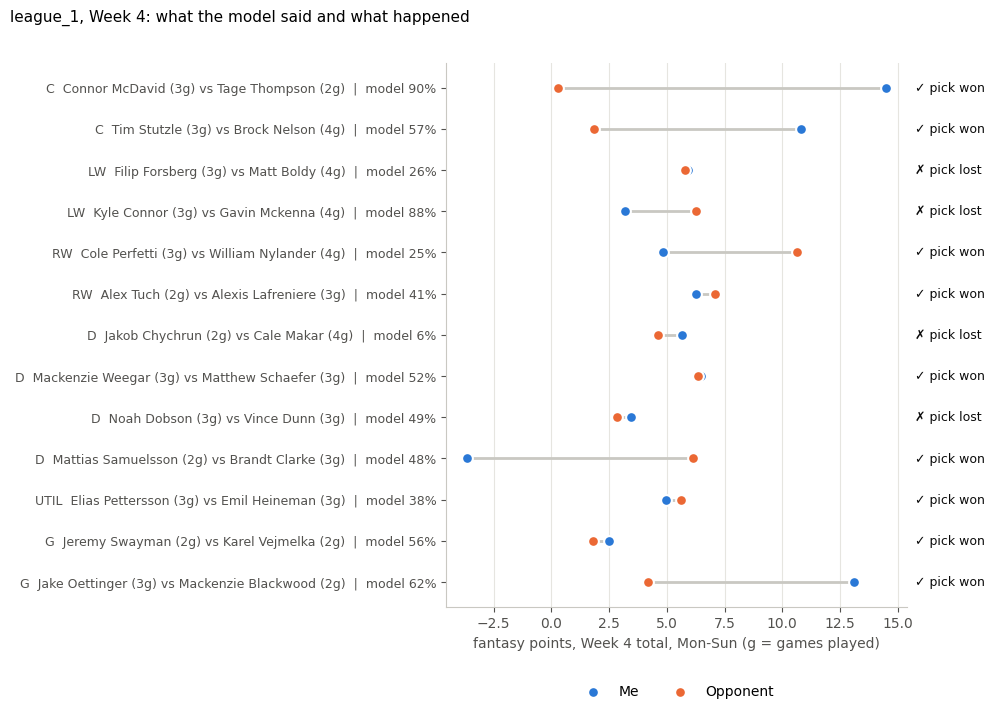

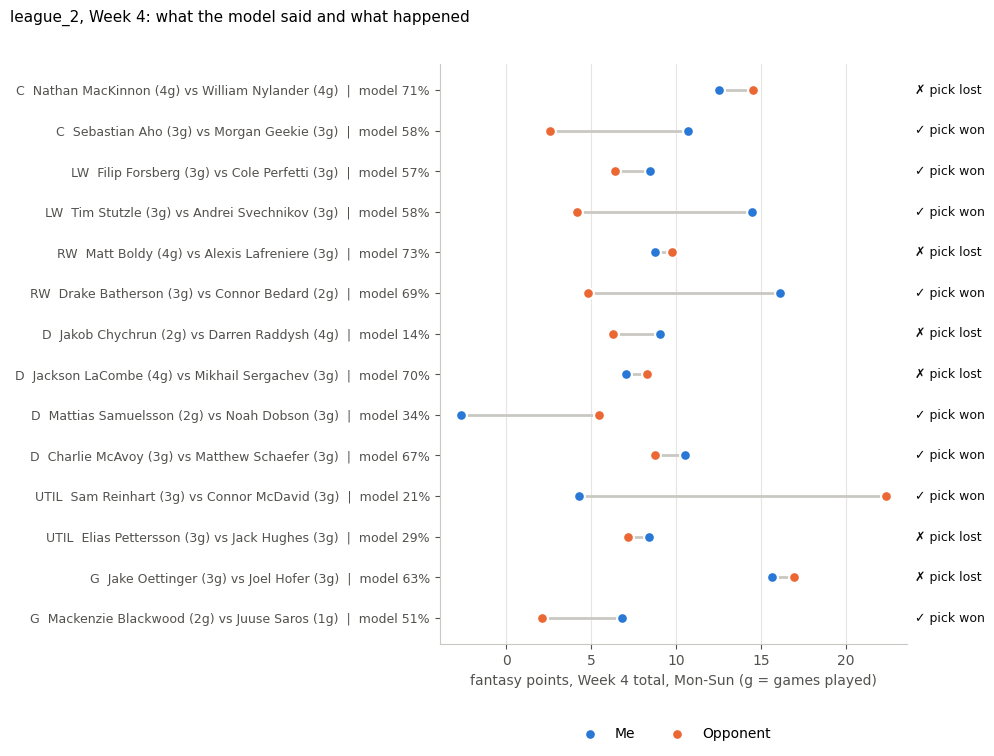

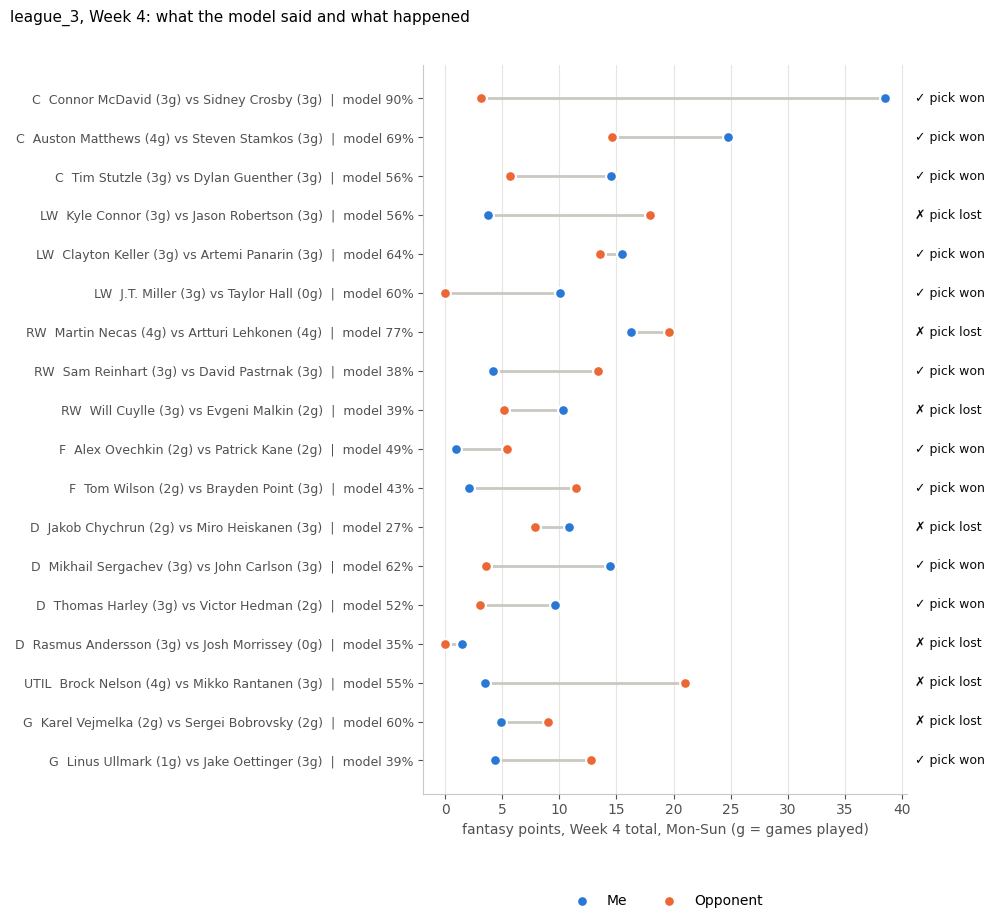

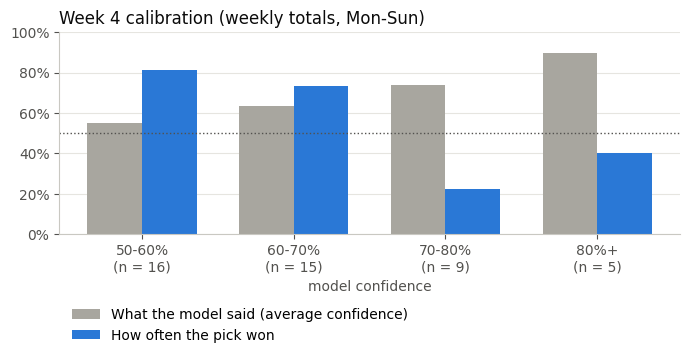

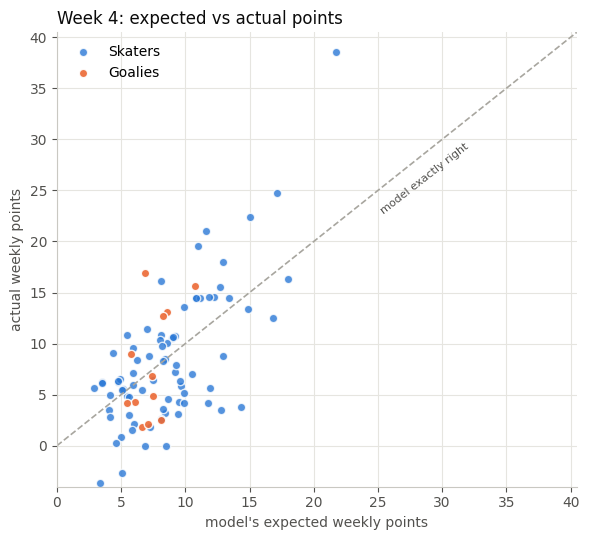

In [21]:
def plot_week4_matchups(league):
    d = recap4[recap4["league"] == league].reset_index(drop=True)
    y = np.arange(len(d))[::-1]
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(d) + 1.8))
    for yi, r in zip(y, d.itertuples()):
        ax.plot([r.me_total, r.opp_total], [yi, yi], color="#c9c8c2", linewidth=2, zorder=1)
    ax.scatter(d["me_total"], y, s=60, color=BLUE, zorder=3, label="Me", edgecolor="white", linewidth=1.5)
    ax.scatter(d["opp_total"], y, s=60, color=ORANGE, zorder=3, label="Opponent", edgecolor="white", linewidth=1.5)
    labels = [f"{r.position}  {r.me} ({r.me_games_actual}g) vs {r.opponent} ({r.opp_games_actual}g)  |  model {r.p_me_outperforms:.0%}"
              for r in d.itertuples()]
    ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=9)
    right = ax.get_xlim()[1]
    for yi, r in zip(y, d.itertuples()):
        sym, txt = ("✓", "pick won") if r.pick_won == 1 else (("=", "tie") if r.pick_won == 0.5 else ("✗", "pick lost"))
        ax.text(right, yi, f"  {sym} {txt}", va="center", fontsize=9, color=INK, clip_on=False)
    ax.set_xlabel("fantasy points, Week 4 total, Mon-Sun (g = games played)")
    fig.suptitle(f"{league}, Week 4: what the model said and what happened", x=0.01, ha="left", fontsize=11)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False, ncol=2)
    ax.grid(axis="y", visible=False)
    plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

for lg in sorted(recap4["league"].unique()):
    plot_week4_matchups(lg)

cal = recap4.groupby("bucket10", observed=False).agg(n=("pick_won","size"),
      avg_conf=("confidence","mean"), hit=("pick_won","mean")).reset_index()
cal = cal[cal["n"] > 0]
x = np.arange(len(cal)); w = 0.36
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - w/2, cal["avg_conf"], w, color=GRAY, label="What the model said (average confidence)")
ax.bar(x + w/2, cal["hit"], w, color=BLUE, label="How often the pick won")
ax.axhline(0.5, color=MUTED, linewidth=1, linestyle=":")
ax.set_xticks(x); ax.set_xticklabels([f"{b}\n(n = {n})" for b, n in zip(cal["bucket10"].astype(str), cal["n"])])
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("model confidence"); ax.set_title("Week 4 calibration (weekly totals, Mon-Sun)", loc="left")
ax.legend(loc="upper left", frameon=False, bbox_to_anchor=(0, -0.3))
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 5.5))
sk, gl = pts[pts["position"] != "G"], pts[pts["position"] == "G"]
ax.scatter(sk["pred"], sk["actual"], s=36, color=BLUE, alpha=0.8, edgecolor="white", label="Skaters")
ax.scatter(gl["pred"], gl["actual"], s=36, color=ORANGE, alpha=0.9, edgecolor="white", label="Goalies")
lim = max(pts["pred"].max(), pts["actual"].max()) * 1.05
ax.plot([0, lim], [0, lim], color=GRAY, linewidth=1.2, linestyle="--")
ax.text(lim*0.62, lim*0.56, "model exactly right", color=MUTED, fontsize=8, rotation=38)
ax.set_xlim(0, lim); ax.set_ylim(min(0, pts["actual"].min()) * 1.1, lim)
ax.set_xlabel("model's expected weekly points"); ax.set_ylabel("actual weekly points")
ax.set_title("Week 4: expected vs actual points", loc="left")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

In [22]:
def scoreboard_block_w4():
    n, won = len(recap4), recap4["pick_won"].sum()
    eq = recap4["me_games"] == recap4["opp_games"]
    lines = [
        "**Week 4 results (weekly-total probabilities, Mon-Sun window)**", "",
        f"- All matchups: {won:.1f} of {n} picks won ({won/n:.1%}), Brier {recap4['brier'].mean():.3f}",
        f"- Unequal games: {recap4[~eq]['pick_won'].sum():.1f} of {(~eq).sum()}",
        f"- Equal games: {recap4[eq]['pick_won'].sum():.1f} of {eq.sum()}",
        "", "| Confidence | n | Won | Avg confidence | Hit rate |", "|---|---|---|---|---|",
    ]
    t = recap4.groupby("bucket10", observed=False).agg(n=("pick_won","size"), won=("pick_won","sum"),
            avg=("confidence","mean"), hit=("pick_won","mean"))
    for label, r in t.iterrows():
        if r["n"]:
            lines.append(f"| {label} | {int(r['n'])} | {r['won']:.0f} | {r['avg']:.1%} | {r['hit']:.1%} |")
    lines += ["", "Brier reference: 0.250 = always 50%."]
    return "\n".join(lines)

print(scoreboard_block_w4())

**Week 4 results (weekly-total probabilities, Mon-Sun window)**

- All matchups: 28.0 of 45 picks won (62.2%), Brier 0.283
- Unequal games: 11.0 of 20
- Equal games: 17.0 of 25

| Confidence | n | Won | Avg confidence | Hit rate |
|---|---|---|---|---|
| 50-60% | 16 | 13 | 54.9% | 81.2% |
| 60-70% | 15 | 11 | 63.5% | 73.3% |
| 70-80% | 9 | 2 | 73.7% | 22.2% |
| 80%+ | 5 | 2 | 89.8% | 40.0% |

Brier reference: 0.250 = always 50%.


In [28]:
# Running record across the weekly-total weeks (Weeks 2 to 4)
!wget -q -O predictions/week02_results.csv https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/predictions/week02_results.csv
!wget -q -O predictions/week03_results.csv https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/predictions/week03_results.csv
try:
    r2 = pd.read_csv("predictions/week02_results.csv")
    r3 = pd.read_csv("predictions/week03_results.csv")
    both = pd.concat([r2.assign(week=2), r3.assign(week=3), recap4.assign(week=4)], ignore_index=True)
    both["bucket10"] = pd.cut(both["confidence"], [0.5,0.6,0.7,0.8,1.01], right=False, labels=["50-60%","60-70%","70-80%","80%+"])
    eqb = both["me_games"] == both["opp_games"]
    print(f"\nWeeks 2+3+4: {both['pick_won'].sum():.1f} of {len(both)} ({both['pick_won'].mean():.1%}), Brier {both['brier'].mean():.3f}")
    print(f"  equal games:   {both[eqb]['pick_won'].sum():.1f} of {eqb.sum()}")
    print(f"  unequal games: {both[~eqb]['pick_won'].sum():.1f} of {(~eqb).sum()}")
    print(both.groupby("bucket10", observed=False).agg(n=("pick_won","size"), won=("pick_won","sum"), hit=("pick_won","mean")).to_string(float_format=lambda v: f"{v:.3f}"))
except Exception as e:
    print("Running record skipped:", e)

Running record skipped: No columns to parse from file


**TODO:** the running-record cell above only counts Week 4 until `week02_results.csv` and `week03_results.csv` are on main. Push both, then re-run it. Expected result: 84 of 134 (62.7%) across Weeks 2 to 4. If it differs, correct the Weeks 2 to 4 numbers in "What I take from Week 4".

**What I take from Week 4:**

(Write this after the outputs above. Compare against the Week 3 result, the equal-games record, the headline picks, and goalie appearances against start share.)

**What I take from Week 4:**
- 28 of 45 picks won (62.2%), but Brier was 0.283, worse than the 0.250 of always predicting 50%. League 1 went 9 of 13 (0.297), league 2 8 of 14 (0.309), league 3 11 of 18 (0.254).
- The problem is the top end. Calls at 50-60% won 13 of 16 (81%) and 60-70% won 11 of 15 (73%), but 70-80% won only 2 of 9 (22%) and 80%+ only 2 of 5 (40%). The most confident calls are the ones that failed.
- Across Weeks 2 to 4 (weekly totals, 134 matchups, 84 won, 62.7%), the hit rate does not rise with confidence: 50-60% 29 of 46 (63%), 60-70% 30 of 48 (63%), 70-80% 14 of 24 (58%), 80%+ 11 of 16 (69%). One bad week of top-end calls drives most of it, so this is a pattern to track for the Week 6 review and not a reason to change anything now.
- The point estimates are fine: mean expected 8.53 vs mean actual 8.32, correlation 0.67 (up from 0.55 and 0.44). That points at the spread, not the averages, so the probabilities may be too extreme.
- Headline picks went 1 of 3. McDavid won (38.55 vs 3.12), MacKinnon lost (12.55 vs 14.55), and Makar over Chychrun lost (4.60 vs 5.65). Chychrun, with 2 games to Makar's 4, also beat Raddysh in league 2 at 14%.
- Unequal-game calls won 11 of 20 and equal-game calls 17 of 25, so the schedule edge did not show up this week. Availability was part of it: Taylor Hall and Josh Morrissey played 0 of 3 games, and Malkin and Hedman 2 of 3. The model assumes everyone plays every team game.
- Goalies made 26 appearances against 24.0 expected, and came in 0.46 above expectation (skaters 0.31 below).

## Week 4 sleepers, did the thesis show up?

In [24]:
SEASON_START, PRE_WEEK_END = "2026-09-01", "2026-10-18"   # "before Week 4" = everything through Sunday Oct 18

rows = []
for name in SLEEPERS_W4:
    pos = SLEEPER_POSITION.get(name, "F")
    pid = resolve_id(name)
    for league in ("league_1", "league_2", "league_3"):
        cfg, fmap = cfg_and_map(league, pos)
        w4 = window_stats(name, pos, league, *WEEK4[league])
        pre = window_stats(name, pos, league, SEASON_START, PRE_WEEK_END)
        w4_avg = w4["total"] / w4["games"] if w4["games"] else np.nan
        pre_avg = pre["total"] / pre["games"] if pre["games"] else np.nan
        last_avg, _ = get_prior_season_stats(pid, PRIOR_SEASON, pos, cfg, fmap)
        rows.append({"player": name, "league": league, "week4_games": w4["games"], "week4_avg": w4_avg,
                     "pre_week_avg": pre_avg, "last_season_avg": last_avg,
                     "vs_pre_week": (w4_avg / pre_avg - 1) if pre_avg and not pd.isna(w4_avg) else np.nan,
                     "vs_last_season": (w4_avg / last_avg - 1) if last_avg and not pd.isna(w4_avg) else np.nan})
sleepers_w4_recap = pd.DataFrame(rows)
print(sleepers_w4_recap.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

Matched 'Adam Edstrom' to 'Adam Edstrom'
Pulling fresh game log for 8481726, 20262027
Loading game log for 8481726, 20262027 from cache, 0.0 hours old
Loading game log for 8481726, 20252026 from cache, 0.3 hours old
Loading game log for 8481726, 20262027 from cache, 0.0 hours old
Loading game log for 8481726, 20262027 from cache, 0.0 hours old
Loading game log for 8481726, 20252026 from cache, 0.3 hours old
Loading game log for 8481726, 20262027 from cache, 0.0 hours old
Loading game log for 8481726, 20262027 from cache, 0.0 hours old
Loading game log for 8481726, 20252026 from cache, 0.3 hours old
Matched 'Michael Brandsegg-Nygard' to 'Michael Brandsegg-Nygård'
Pulling fresh game log for 8484794, 20262027
Loading game log for 8484794, 20262027 from cache, 0.0 hours old
Loading game log for 8484794, 20252026 from cache, 0.3 hours old
Loading game log for 8484794, 20262027 from cache, 0.0 hours old
Loading game log for 8484794, 20262027 from cache, 0.0 hours old
Loading game log for 848

In [25]:
periods = (("Before Week 4", SEASON, SEASON_START, PRE_WEEK_END),
           ("Week 4", SEASON, *WEEK4["league_1"]),
           ("Last season", PRIOR_SEASON, None, None))
skater_rows, goalie_rows = [], []
for name in SLEEPERS_W4:
    for label, season, s, e in periods:
        if SLEEPER_POSITION.get(name, "F") == "G":
            r = goalie_process(name, season, s, e)
            if r: goalie_rows.append({"player": name, "period": label, **r})
        else:
            r = process_window(name, season, s, e)
            if r: skater_rows.append({"player": name, "period": label, **r})

sleepers_process_w4r = pd.DataFrame(skater_rows)
sleepers_goalie_w4r = pd.DataFrame(goalie_rows)
print("Skaters:")
print(sleepers_process_w4r.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nGoalie (start_share = starts / his team's games in that window):")
print(sleepers_goalie_w4r.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

Loading game log for 8481726, 20262027 from cache, 0.0 hours old
Loading game log for 8481726, 20262027 from cache, 0.0 hours old
Loading game log for 8481726, 20252026 from cache, 0.3 hours old
Loading game log for 8484794, 20262027 from cache, 0.0 hours old
Loading game log for 8484794, 20262027 from cache, 0.0 hours old
Loading game log for 8484794, 20252026 from cache, 0.3 hours old
Loading game log for 8476432, 20262027 from cache, 0.0 hours old
Loading game log for 8476432, 20262027 from cache, 0.0 hours old
Loading game log for 8476432, 20252026 from cache, 0.3 hours old
Skaters:
                  player        period  games  pts_per_game  shots_per_game  shooting_pct  toi_per_game
            Adam Edstrom Before Week 4      8          0.50            1.88          0.27         13.70
            Adam Edstrom        Week 4      3          0.00            0.67          0.00         15.75
            Adam Edstrom   Last season     35          0.14            0.89          0.10     

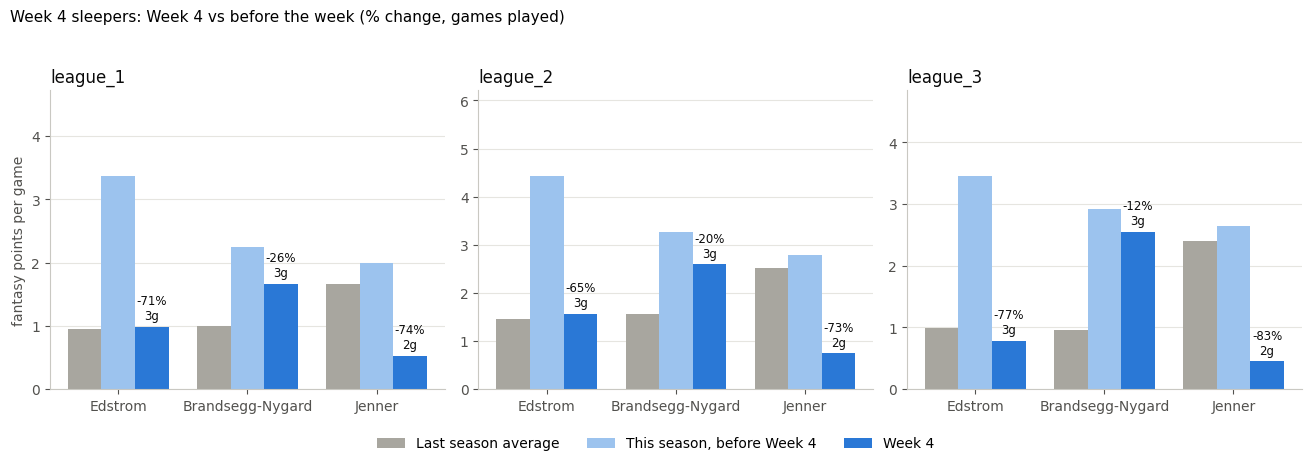

Loading game log for 8481726, 20262027 from cache, 0.0 hours old
Loading game log for 8484794, 20262027 from cache, 0.0 hours old
Loading game log for 8476432, 20262027 from cache, 0.0 hours old


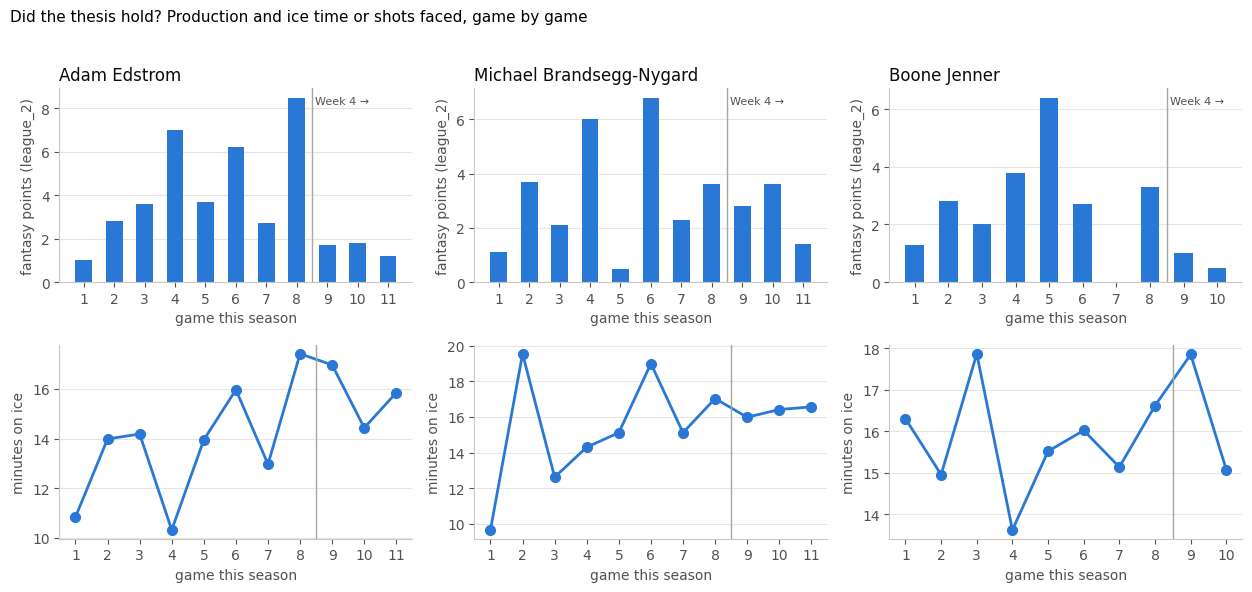

In [26]:
LIGHT = "#9cc3ee"

def plot_sleeper_recap_w4(df):
    leagues = sorted(df["league"].unique())
    players = list(dict.fromkeys(df["player"]))
    fig, axes = plt.subplots(1, len(leagues), figsize=(4.4 * len(leagues), 4.6))
    axes = np.atleast_1d(axes)
    x = np.arange(len(players)); w = 0.26
    for ax, league in zip(axes, leagues):
        d = df[df["league"] == league].set_index("player").loc[players]
        ax.bar(x - w, d["last_season_avg"], w, color=GRAY, label="Last season average")
        ax.bar(x, d["pre_week_avg"], w, color=LIGHT, label="This season, before Week 4")
        ax.bar(x + w, d["week4_avg"], w, color=BLUE, label="Week 4")
        top = np.nanmax(d[["last_season_avg", "pre_week_avg", "week4_avg"]].values)
        for xi, (_, r) in zip(x, d.iterrows()):
            if pd.notna(r["week4_avg"]):
                lab = f"{r['vs_pre_week']:+.0%}\n{int(r['week4_games'])}g" if pd.notna(r["vs_pre_week"]) else f"{int(r['week4_games'])}g"
                ax.text(xi + w, r["week4_avg"] + top * 0.02, lab, ha="center", va="bottom", fontsize=8.5, color=INK)
        ax.set_ylim(0, top * 1.4)
        ax.set_xticks(x); ax.set_xticklabels([p.split()[-1] for p in players])
        ax.set_title(league, loc="left"); ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("fantasy points per game")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=3, frameon=False)
    fig.suptitle("Week 4 sleepers: Week 4 vs before the week (% change, games played)", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0.07, 1, 0.95)); plt.show()

plot_sleeper_recap_w4(sleepers_w4_recap)

def plot_sleeper_games_w4r(league="league_2"):
    n = len(SLEEPERS_W4)
    fig, axes = plt.subplots(2, n, figsize=(4.2 * n, 6), squeeze=False)
    for j, name in enumerate(SLEEPERS_W4):
        pos = SLEEPER_POSITION.get(name, "F")
        cfg, fmap = cfg_and_map(league, pos)
        pid = resolve_id(name)
        cur = _scored_game_log(pid, SEASON, pos, cfg, fmap, force_refresh=False)
        ax, ax2 = axes[0, j], axes[1, j]
        if cur is None or cur.empty:
            ax.set_title(f"{name}: no games yet", loc="left"); continue
        cur = cur[cur["gameDate"] <= pd.Timestamp(WEEK4["league_1"][1])].reset_index(drop=True)
        g = np.arange(1, len(cur) + 1)
        split = int((cur["gameDate"] < pd.Timestamp(WEEK4["league_1"][0])).sum()) + 0.5
        ax.bar(g, cur["fantasy_points"], color=BLUE, width=0.55)
        ax.axvline(split, color=GRAY, linewidth=1)
        ax.text(split + 0.1, ax.get_ylim()[1] * 0.92, "Week 4 →", color=MUTED, fontsize=8)
        ax.set_title(name, loc="left"); ax.set_xticks(g); ax.set_xlabel("game this season")
        ax.set_ylabel(f"fantasy points ({league})"); ax.grid(axis="x", visible=False)
        if pos == "G" and "shotsAgainst" in cur.columns:
            ax2.bar(g, pd.to_numeric(cur["shotsAgainst"], errors="coerce"), color=ORANGE, width=0.55)
            ax2.set_ylabel("shots against")
        elif "toi" in cur.columns:
            ax2.plot(g, cur["toi"].map(toi_minutes), color=BLUE, linewidth=2, marker="o", markersize=7)
            ax2.set_ylabel("minutes on ice")
        ax2.axvline(split, color=GRAY, linewidth=1)
        ax2.set_xticks(g); ax2.set_xlabel("game this season"); ax2.grid(axis="x", visible=False)
    fig.suptitle("Did the thesis hold? Production and ice time or shots faced, game by game", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

plot_sleeper_games_w4r("league_2")

In [27]:
sleepers_w4_recap.to_csv("predictions/sleepers_week04_results.csv", index=False)
print("Saved predictions/sleepers_week04_results.csv")

Saved predictions/sleepers_week04_results.csv


Fantasy points per game in Week 4 against the same player's season before the week, and against last season:

| Player | Week 4 games | League 1 | League 2 | League 3 |
|---|---|---|---|---|
| Edström vs before Week 4 | 3 | -71% | -65% | -77% |
| Edström vs last season | 3 | +3% | +7% | -21% |
| Brandsegg-Nygard vs before Week 4 | 3 | -26% | -20% | -12% |
| Brandsegg-Nygard vs last season | 3 | +67% | +68% | +166% |
| Jenner vs before Week 4 | 2 | -74% | -73% | -83% |
| Jenner vs last season | 2 | -68% | -70% | -81% |

| Player | Period | Games | Detail |
|---|---|---|---|
| Edström | Before Week 4 | 8 | 0.50 pts/g, 1.88 shots/g, 27% shooting, 13.7 min |
| Edström | Week 4 | 3 | 0.00 pts/g, 0.67 shots/g, 0% shooting, 15.8 min |
| Brandsegg-Nygard | Before Week 4 | 8 | 0.75 pts/g, 2.75 shots/g, 9% shooting, 15.3 min |
| Brandsegg-Nygard | Week 4 | 3 | 0.67 pts/g, 1.67 shots/g, 0% shooting, 16.3 min |
| Jenner | Before Week 4 | 8 | 0.62 pts/g, 2.75 shots/g, 18% shooting, 15.8 min |
| Jenner | Week 4 | 2 | 0.00 pts/g, 1.50 shots/g, 0% shooting, 16.5 min |

Against the theses I wrote before the games:
- **Edström: only the first half held.** The goals did not last (0 goals at 0% shooting), as I said. But shots fell from 1.88 to 0.67 per game, his points per game ended about flat with last season in leagues 1 and 2 and below it in league 3, and he finished far below his projection (0.98, 1.57 and 0.78 against 2.03, 2.78 and 2.09).
- **Brandsegg-Nygard held.** Ice time rose to 16.3 minutes, he stayed well above last season in every league (+67% to +166%), and he beat his projection, though shots fell to 1.67 per game and the points came as assists.
- **Jenner did not hold.** I said shots would stay up about 40% and they fell to 1.50 per game, below last season's 1.97. His points fell 68% to 81% below last season, on 2 games.

One of three held on its own thesis, the same as Week 3. Across three weeks of sleepers it is 2 of 9. That is a small sample, but all three players fell below their pre-week averages, so the process numbers did not predict the week.

(Optional) update `SCOREBOARD.md` with the Week 4 results, the Week 4 sleeper results, and the new Week 5 predictions.